# Logistic Regression Baseline v2

**Question** Will a kidney waitlist candidate die or be removed as too sick **within 365 days of listing**?



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

pd.set_option('display.width', 200)

RANDOM_STATE = 42
FOLLOWUP_END = pd.Timestamp('2026-07-03')   # last follow-up date in the extract
WINDOW_DAYS = 365
RAW_PATH = "../data/restricted/kidney_waitlist_analytic.csv.gz"

## 1. Load data

In [2]:
df  = pd.read_csv("../data/processed/model_table.csv.gz", index_col=0)
raw = pd.read_csv("../data/processed/cleaned_waitlist.csv")
assert len(df) == len(raw) and df.index.equals(raw.index), "model_table and cleaned_waitlist are misaligned"

# Original (pre-imputation) values, only to learn which cPRA / BMI values were missing.
# Apply the same bad-date filter as the outliers notebook so rows line up, then verify with the listing ID.
orig = pd.read_csv(RAW_PATH, usecols=['WL_ID_CODE', 'INIT_DATE', 'END_DATE', 'INIT_CPRA', 'BMI_TCR'])
orig = orig.loc[~(orig['END_DATE'] < orig['INIT_DATE'])].reset_index(drop=True)
assert len(orig) == len(raw) and (orig['WL_ID_CODE'].to_numpy() == raw['WL_ID_CODE'].to_numpy()).all(), \
    "raw extract does not line up with cleaned_waitlist"

print(df.shape)

(494803, 46)


## 2. Target and eligible rows 
- 80/20 split 
    - 353,804 training rows, adverse event rate of 3.77%
    - 88,278 testing rows, adverse event reate of 3.87%

In [3]:
init_date = pd.to_datetime(raw['INIT_DATE'])

y = ((raw['event_adverse'] == 1) & (raw['days_to_event'] <= WINDOW_DAYS)).astype(int)
eligible = init_date <= FOLLOWUP_END - pd.Timedelta(days=WINDOW_DAYS)

is_test = df['is_test'].astype(bool)
tr, te = (~is_test & eligible), (is_test & eligible)
groups = df['PT_CODE']

print("train rows:", tr.sum(), "| test rows:", te.sum())
print("1-yr event rate  train:", round(y[tr].mean(), 4), "| test:", round(y[te].mean(), 4))

train rows: 353804 | test rows: 88278
1-yr event rate  train: 0.0377 | test: 0.0387


## 2a. Things to Note

### Why a 365-day window

- In original data, someone listed in 2015 has had 11 years to experience an adverse event, while someone listed in 2026 has had only a few months. The original `event_adverse` label marks both as 0 if nothing has happened *yet*. Recent patients therefore look low-risk when they simply have not been observed for long enough.
- What the model would learn: Using that label, the model learns "recently listed = low risk" from any feature that tracks listing year. That reflects follow-up time, not the patient's health.
- What the fixed window does: The 1-year label asks the same question of everyone: *did an adverse event happen within 365 days of listing?*
    - 1 = died or was removed as too sick within the first 365 days
    - 0 = everyone else, including patients who had an event later, were transplanted, or were still waiting
- Who is included:  Only patients who have at least a year worth of data.


- **Analysis**
    - Each full year has roughly 29,000 to 42,500 training listings (2026 has 20,783 because it covers only half a year), so the differences below are not caused by some years having very few patients.
    - adverse_rate` drops from 22.9% for 2015 listings to 0.6% for 2026. This is not because recent patients are healthier. It is because an adverse event takes time to happen, and recent patients have not been observed for long.
    -  `adverse_rate_1yr` stays between 3.3% and 4.4% for every year from 2015 to 2024. When every patient is given the same 365 days, the apparent decline disappears, which shows the decline came from follow-up time and not from patient health.
    - Most adverse events happen after the first year. For 2015 listings, 22.9% eventually had an adverse event but only 4.0% had one within a year. The 1-year model therefore captures short-term risk only.
    - 2025 and 2026 are incomplete. Their 1-year rates (2.9% and 0.6%) are low because many of these patients have not yet had a full year. For 2026 the two rates are identical (0.6%), since nobody listed in 2026 has more than about six months of follow-up. These patients are excluded from model training by the `eligible` filter.
    - `censored_share` is the fraction of patients still waiting when follow-up ended: no transplant, no adverse event, no removal. It rises from 0.8% for 2015 to 83.6% for 2026.

In [4]:
train_all = ~is_test   

tab = pd.DataFrame({
    'year': init_date.dt.year[train_all],
    'adverse': raw.loc[train_all, 'event_adverse'],    # ORIGINAL label, not the 1-year one
    'adverse_1yr': y[train_all],                       # 1-year label, for comparison
    'censored': raw.loc[train_all, 'censored']})

print(tab.groupby('year').agg(n=('adverse', 'size'),
                              adverse_rate=('adverse', 'mean'),
                              adverse_rate_1yr=('adverse_1yr', 'mean'),
                              censored_share=('censored', 'mean')).round(3))

          n  adverse_rate  adverse_rate_1yr  censored_share
year                                                       
2015  29315         0.229             0.040           0.008
2016  29537         0.213             0.038           0.012
2017  29833         0.202             0.037           0.017
2018  32398         0.193             0.033           0.026
2019  34536         0.193             0.037           0.042
2020  30220         0.180             0.044           0.065
2021  33570         0.157             0.041           0.107
2022  35695         0.133             0.038           0.168
2023  37604         0.102             0.035           0.257
2024  39896         0.072             0.038           0.386
2025  42502         0.034             0.029           0.594
2026  20783         0.006             0.006           0.836


## 3. 

`dialysis_started_after_listing` had the strongest coefficient in my first model. A dialysis start date after the listing date can only have been entered after listing, so it is not available on listing day. A patient has to survive long enough to start dialysis.

- **Analysis**
    - First Chart 
        - All 42,372 patients whose dialysis began after listing are recorded as `ON_DIALYSIS = Y`, so this field was updated after listing and does not describe the patient on listing day. `ON_DIALYSIS = Y` is leakage and is removed; because the model can use this information and conclude that “this person survived a while”. 
    - Second Chart 
        - Patients whose dialysis began after listing have a 1-year adverse rate of 0.71%, 
        - Patients whose dialysis began on/before listing have a 1-year adverse rate of 4.13%. 
            - Patients who start 
- `dialysis_started_after_listing` and `ON_DIALYSIS` are replaced by `on_dialysis_at_listing`
    - 1 only when the dialysis date is on or before the listing date
    - 0 dialysis began after listing or no dialysis date

In [5]:
dial_date = pd.to_datetime(raw['DIALYSIS_DATE'], errors='coerce')   # 'Not on dialysis' -> NaT

timing = pd.Series(np.select(
    [dial_date.isna(), dial_date > init_date],
    ['no dialysis date', 'dialysis began AFTER listing'],
    default='dialysis on/before listing'), index=raw.index, name='dialysis timing')

print(pd.crosstab(raw['ON_DIALYSIS'], timing), "\n")

# timing for patients at least 1 year of data
print(pd.DataFrame({'timing': timing, 'y': y})[eligible]
        .groupby('timing')['y'].agg(n='size', adverse_rate_1yr='mean').round(4))

dialysis timing  dialysis began AFTER listing  dialysis on/before listing  no dialysis date
ON_DIALYSIS                                                                                
N                                           0                           0            134235
Y                                       42372                      318196                 0 

                                   n  adverse_rate_1yr
timing                                                
dialysis began AFTER listing   41498            0.0071
dialysis on/before listing    285096            0.0413
no dialysis date              115488            0.0404


## 4. Improving the Logistic Regression: Build the feature sets

Each set adds one idea to the previous one, so the ablation table can show the effect of each.

| Set | What changes |
| --- | --- |
| F0 | v1 features, unchanged (reproduces the old result) |
| F1 | drop post-listing fields; add `on_dialysis_at_listing` |
| F2 | + cPRA / BMI missing flags, `cpra_positive`, log dialysis time |
| F3 | + splines for age and BMI, + two interactions |
| F4 | + `prior_listings` |



In [6]:
base = df.drop(columns=['event_adverse', 'is_test', 'PT_CODE'])

# F0: v1 features
F0 = base.copy()

# F1: drop leaky columns from dialy`dialysis_started_after_listing` and `ON_DIALYSIS`
leaky_cols = ['dialysis_started_after_listing', 'ON_DIALYSIS_Y'] + \
             [c for c in base.columns if c.startswith('A2A2B_ELIGIBILITY')]
leaky_cols = [c for c in leaky_cols if c in base.columns]
print("dropping:", leaky_cols)

F1 = base.drop(columns=leaky_cols)
F1['on_dialysis_at_listing'] = (dial_date <= init_date).astype(float)   # NaT compares False
# dialysis_duration_days is already 0 for 'no date' and 'began after listing' (set in encoding_scaling)

# F2: earlier notebooks filled missing cPRA and BMI with median which distorts a true cPRA of 0 vs there is no data; this restores it
# a few patients have 30+ years on dialysis, this stops extreme values from dominating
F2 = F1.copy()
F2['cpra_missing']  = orig['INIT_CPRA'].isna().astype(float).to_numpy()
F2['cpra_positive'] = ((orig['INIT_CPRA'] > 0).astype(float)).to_numpy()
F2['bmi_missing_or_invalid'] = (~orig['BMI_TCR'].between(10, 80)).astype(float).to_numpy()   # NaN -> flagged
F2['dialysis_log'] = np.log1p(F2['dialysis_duration_days'])
F2 = F2.drop(columns=['dialysis_duration_days'])

# F3: let one feature’s effect depend on another. 
# e.g. five years on dialysis may mean something different for a 30yothan for a 70yo.
F3 = F2.copy()
age_c = (F3['INIT_AGE'] - 50) / 15
F3['age_x_dialysis']   = age_c * (F3['dialysis_log'] - 4)
F3['age_x_functional'] = age_c * (F3['functional_percent'] - 80) / 10
SPLINE_COLS = ['INIT_AGE', 'BMI_TCR']

# F4: A patient on their second or third listing has a different history from a first-time patient
# they may have had a failed transplant, or been removed and relisted. (this information is being used)
F4 = F3.copy()
prior = init_date.groupby(raw['PT_CODE']).rank(method='min') - 1
F4['prior_listings'] = prior.clip(upper=3)

print("prior listings (all rows):")
print(F4['prior_listings'].value_counts().sort_index())
for name, F in [('F0', F0), ('F1', F1), ('F2', F2), ('F3', F3), ('F4', F4)]:
    assert np.isfinite(F.to_numpy(dtype=float)).all(), name + " has non-finite values"
    print(name, F.shape)

dropping: ['dialysis_started_after_listing', 'ON_DIALYSIS_Y', 'A2A2B_ELIGIBILITY_1.0', 'A2A2B_ELIGIBILITY_NA_value']
prior listings (all rows):
prior_listings
0.0    415556
1.0     63421
2.0     12027
3.0      3799
Name: count, dtype: int64
F0 (494803, 43)
F1 (494803, 40)
F2 (494803, 43)
F3 (494803, 45)
F4 (494803, 46)


*Some patients are listed multiple times: 494,803 rows but only 414,130 unique patients*
- 415,556 rows are a patient’s first listing.
- 63,421 rows are a patient’s second listing (1 before it).
- 12,027 rows are a third listing (2 before it).
- 3,799 rows are a fourth listing or later (3 or more before it).


## 5. Ablation: what did each change do?

In [7]:
CONTINUOUS = ['BMI_TCR', 'INIT_CPRA', 'INIT_AGE', 'functional_percent', 'dialysis_duration_days',
              'dialysis_log', 'age_x_dialysis', 'age_x_functional', 'prior_listings']

def make_model(columns, spline_cols=(), C=1.0):
    # scaling (and spline knots) are learned from the training rows only, inside the pipeline
    spline_cols = [c for c in spline_cols if c in columns]
    num_cols = [c for c in CONTINUOUS if c in columns and c not in spline_cols]
    pre = ColumnTransformer(
        [('spline', make_pipeline(SplineTransformer(n_knots=5, degree=3, knots='quantile', include_bias=False),
                                  StandardScaler()), spline_cols),
         ('num', StandardScaler(), num_cols)],
        remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(pre, LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE))

def top_decile_lift(y_true, p):
    y_true = np.asarray(y_true)
    k = len(y_true) // 10
    top = np.argsort(p)[::-1][:k]
    return y_true[top].mean() / y_true.mean()

def score(y_true, p):
    base_rate = y_true.mean()
    brier = brier_score_loss(y_true, p)
    return {'ROC-AUC': roc_auc_score(y_true, p),
            'PR-AUC': average_precision_score(y_true, p),
            'PR-AUC / base': average_precision_score(y_true, p) / base_rate,
            'Lift@10%': top_decile_lift(y_true, p),
            'Brier': brier,
            'Brier skill': 1 - brier / (base_rate * (1 - base_rate))}   # % better than predicting the base rate

def fit_eval(F, spline_cols=(), C=1.0, target=None, train=None, test=None):
    target = y if target is None else target
    train  = tr if train is None else train
    test   = te if test is None else test
    model = make_model(list(F.columns), spline_cols, C).fit(F[train], target[train])
    p = model.predict_proba(F[test])[:, 1]
    return model, p, score(target[test], p)

steps = [('F0  v1 features (old result)',            F0, ()),
         ('F1  post-listing fields removed',         F1, ()),
         ('F2  + missing flags, log dialysis',       F2, ()),
         ('F3  + splines (age, BMI), interactions',  F3, SPLINE_COLS),
         ('F4  + prior listings',                    F4, SPLINE_COLS)]

rows = {}
for name, F, sp in steps:
    _, _, rows[name] = fit_eval(F, sp)

ablation = pd.DataFrame(rows).T
ablation['ROC-AUC change'] = ablation['ROC-AUC'].diff()
print(ablation.round(4).to_string())

/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ 

                                        ROC-AUC  PR-AUC  PR-AUC / base  Lift@10%   Brier  Brier skill  ROC-AUC change
F0  v1 features (old result)             0.6925  0.0893         2.3089    2.5200  0.0364       0.0215             NaN
F1  post-listing fields removed          0.6801  0.0862         2.2289    2.4467  0.0364       0.0194         -0.0124
F2  + missing flags, log dialysis        0.6790  0.0854         2.2089    2.4467  0.0364       0.0193         -0.0011
F3  + splines (age, BMI), interactions   0.6811  0.0869         2.2470    2.5171  0.0364       0.0200          0.0021
F4  + prior listings                     0.6820  0.0876         2.2646    2.5493  0.0364       0.0203          0.0010


/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


- **Analysis**
    - F0 reproduces the v1 result exactly (ROC-AUC 0.6925), confirming version 2 uses the same patients, split and target.
    - Removing the post-listing fields lowers ROC-AUC from 0.6925 to 0.6801 (−0.0124). About 0.012 of the v1 score came from information not available on listing day. F1 is the honest baseline.
    - Missing-value flags, log dialysis time, splines, interactions and prior listings together raise ROC-AUC from 0.6801 to 0.6820 (+0.0019). This is within the noise of the test set, so these changes do not meaningfully improve the model.
    - PR-AUC stays at about 2.3 times the base rate, and Brier skill stays at about 2%.
    - Lift in the top decile is 2.55, which meets the 2.5 target using listing-day features only.
    - Conclusion: the ROC-AUC target of 0.78 is not reachable with these features. The limit is the information available at listing, not the model or the feature engineering.

## 6. Tune `C` (patient-grouped cross-validation on the training rows)

In [8]:
F_final, SP_final = F4, SPLINE_COLS

cv_splits = list(GroupKFold(n_splits=3).split(F_final[tr], y[tr], groups[tr]))

cv_rows = []
for C in [0.001, 0.01, 0.1, 1.0, 10.0]:
    s = cross_val_score(make_model(list(F_final.columns), SP_final, C), F_final[tr], y[tr],
                        cv=cv_splits, scoring='average_precision', n_jobs=-1)
    cv_rows.append({'C': C, 'cv PR-AUC': s.mean(), 'std': s.std()})
cv_table = pd.DataFrame(cv_rows)
print(cv_table.round(5).to_string(index=False))

best_C = cv_table.loc[cv_table['cv PR-AUC'].idxmax(), 'C']
print("\nbest C:", best_C)

/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocely

     C  cv PR-AUC     std
 0.001    0.08825 0.00156
 0.010    0.09034 0.00150
 0.100    0.09071 0.00138
 1.000    0.09042 0.00121
10.000    0.09044 0.00124

best C: 0.1


/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


Testing to see if amount of regularization matters
-  Five values of `C` were compared using 3-fold cross-validation on the training rows, with folds grouped by patient.
    - Cross-validated PR-AUC ranges from 0.0883 to 0.0907. From `C` = 0.01 to 10 the scores differ by at most 0.0004, which is smaller than the variation between folds (about 0.0013).
    - Regularization strength has no meaningful effect on performance. `C` = 0.1 is used for the final model, but `C` = 1.0 would perform the same

## 7. Final model: test-set metrics and calibration

In [9]:
model, p_test, final = fit_eval(F_final, SP_final, C=best_C)
y_test = y[te]

print(f"Base rate   : {y_test.mean():.4f}")
print(f"ROC-AUC     : {final['ROC-AUC']:.4f}   (target 0.78)")
print(f"PR-AUC      : {final['PR-AUC']:.4f}   ({final['PR-AUC / base']:.2f}x base rate; target 0.65)")
print(f"Brier       : {final['Brier']:.4f}   (skill vs base rate: {final['Brier skill']:.1%})")
print(f"Lift@10%    : {final['Lift@10%']:.2f}   (target 2.5)")
print("coefficients finite:", np.isfinite(model[-1].coef_).all(), "| iterations:", model[-1].n_iter_[0])

/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ 

Base rate   : 0.0387
ROC-AUC     : 0.6822   (target 0.78)
PR-AUC      : 0.0876   (2.26x base rate; target 0.65)
Brier       : 0.0364   (skill vs base rate: 2.0%)
Lift@10%    : 2.51   (target 2.5)
coefficients finite: True | iterations: 30


/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


**Final Model Analysis**
- Base rate   : 0.0387
    - 3.87% of patients had an adverse event within a year. 
- ROC-AUC     : 0.6822  
    - Does it rank a random event above a random non-event? (Moderate)
    - target 0.78
    - a randomly chosen patient with an event gets a higher risk score than one without about 68% of the time (Missed the 0.78 target)
- PR-AUC      : 0.0876  
    - Are the flagged individuals really the ones with events?
    - Of the patients the model flags, about 9% actually had an event
    - Ideal target: 0.65
    - Missed, and not reachable at a 3.9% base rate.
- Brier       : 0.0364   
    - The model’s predicted probabilities are only about 2% closer to what actually happened than a guess that gives every patient the same 3.9% risk (0.0372).
    - Under the target, but only because events are rare. 
- Lift@10%    : 2.51  
    - Does the top group hold more events? (good)
    - 	The riskiest tenth of patients have events at 2.5 times the average rate. 


**Limitations** 
- Prediction needs: no lab values, no other medical conditions, and nothing recorded between listing and outcome. 
- Those are the qualities that most separate a patient who deteriorates from one who doesn’t.

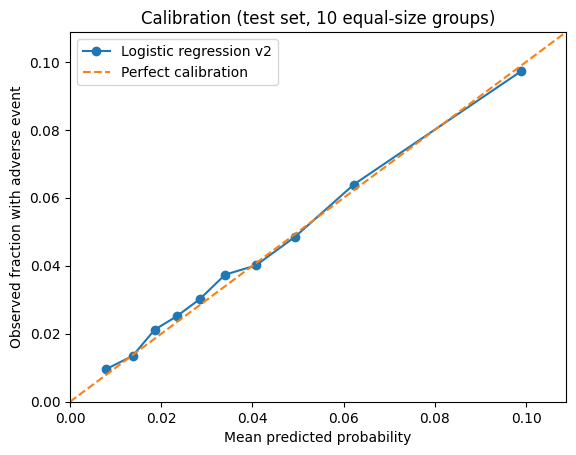

In [10]:
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
lim = max(frac_pos.max(), mean_pred.max()) * 1.1
plt.plot(mean_pred, frac_pos, marker='o', label='Logistic regression v2')
plt.plot([0, lim], [0, lim], '--', label='Perfect calibration')
plt.xlim(0, lim); plt.ylim(0, lim)
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed fraction with adverse event')
plt.title('Calibration (test set, 10 equal-size groups)')
plt.legend(); plt.show()

**Calibration Analysis**
- Are the probabilities accurate? Yes!
    - puts patients in correct order (of low-risk to riskiest)
- 88,278 test patients are sorted by predicted risk and split into 10 equal groups of about 8,800 each
- All 10 points lie on or very close to the diagonal, so the model is well calibrated: its predicted probabilities match the observed rates.
- Observed risk rises steadily from about 1% in the lowest-risk group to about 10% in the highest, a roughly tenfold difference, so the model orders patients correctly.
- The model can describe a patient's risk level reliably but cannot identify individuals who will have an event; explaining why calibration is good while PR-AUC and Brier skill are low.

## 8. What drives the predictions
- how well certain features impact the logistic regression

In [11]:
pre, clf = model[0], model[-1]
names = pre.get_feature_names_out()
coefs = pd.Series(clf.coef_[0], index=names)

is_spline = np.array(['_sp_' in n for n in names])
odds_ratios = np.exp(coefs[~is_spline]).sort_values(ascending=False)
print("Higher risk:\n", odds_ratios.head(8).round(3), "\n")
print("Lower risk:\n",  odds_ratios.tail(8).round(3))

Higher risk:
 bmi_missing_or_invalid             1.941
functional_scale_unknown           1.723
REGION_4                           1.221
INIT_STAT_4099                     1.200
on_dialysis_at_listing             1.152
dialysis_log                       1.085
functional_scale_not_applicable    1.055
age_x_functional                   1.052
dtype: float64 

Lower risk:
 REGION_5              0.827
REGION_9              0.815
ETHCAT_2              0.814
ABO_A1                0.808
REGION_6              0.760
REGION_8              0.756
ETHCAT_5              0.671
functional_percent    0.655
dtype: float64


**Odds Ratio Analysis**

An odds ratio above 1 means higher odds of an adverse event within one year; below 1 means lower. Each is measured with all other features held fixed. Age and BMI are not in this table because they are modelled as curves (see the next plot).

- **Missing or unusable information is the strongest risk signal.**
    - `bmi_missing_or_invalid` (1.94) and `functional_scale_unknown` (1.72) are the two largest odds ratios.
    - A missing value cannot cause risk. These flags are markers for something else, most likely patients who were too unwell to be fully assessed or records that were incomplete at listing.
    - Both groups are small (about 2,100 and 8,700 patients), so the estimates are imprecise.
    - `functional_scale_unknown` behaved differently under the original label, where it tracked recent listings with short follow-up. With the fixed one-year window it now indicates higher risk.
- **Functional status is the strongest clinical predictor.**
    - `functional_percent` (0.655): each standard-deviation increase in functional score (about 14 points) lowers the odds by about a third. Patients who can do more for themselves are at lower risk.
- **Status and dialysis at listing raise risk moderately.**
    - `INIT_STAT_4099` (1.20): patients listed as inactive have 20% higher odds.
    - `on_dialysis_at_listing` (1.15) and `dialysis_log` (1.085): being on dialysis at listing, and for longer, raises risk. These replace the leaky dialysis fields from v1 and point in the expected direction.
- **Region and race/ethnicity differences need careful wording.**
    - Compared with region 1, region 4 has higher odds (1.22) and regions 5, 6, 8 and 9 have lower odds (0.76 to 0.83).
    - Compared with `ETHCAT` 1, `ETHCAT` 2 (0.81) and `ETHCAT` 5 (0.67) have lower odds.
    - These are not evidence of differences in clinical risk. Patients transplanted within the year are labelled 0, so a group that is transplanted faster, or a region with different listing and removal practices, will also show lower odds. The competing-risks models are needed to separate these.
- **Small effects not worth interpreting.**
    - `functional_scale_not_applicable` (1.055) covers only 121 patients.
    - `age_x_functional` (1.052) is an interaction term and is close to 1.
    - `ABO_A1` (0.81) is a small subgroup and should be treated with caution.
- **Overall:** apart from functional status, no single feature moves the odds by much. This matches the modest ROC-AUC of 0.68: risk is spread across many weak signals.

/var/folders/_n/jw5zd1g508l8nh_tjj09sggh0000gn/T/ipykernel_92743/2739754639.py:13: RuntimeWarning: divide by zero encountered in matmul
  log_odds = spline_tf.transform(grid[SP_final]) @ spline_coefs
/var/folders/_n/jw5zd1g508l8nh_tjj09sggh0000gn/T/ipykernel_92743/2739754639.py:13: RuntimeWarning: overflow encountered in matmul
  log_odds = spline_tf.transform(grid[SP_final]) @ spline_coefs
/var/folders/_n/jw5zd1g508l8nh_tjj09sggh0000gn/T/ipykernel_92743/2739754639.py:13: RuntimeWarning: invalid value encountered in matmul
  log_odds = spline_tf.transform(grid[SP_final]) @ spline_coefs
/var/folders/_n/jw5zd1g508l8nh_tjj09sggh0000gn/T/ipykernel_92743/2739754639.py:13: RuntimeWarning: divide by zero encountered in matmul
  log_odds = spline_tf.transform(grid[SP_final]) @ spline_coefs
/var/folders/_n/jw5zd1g508l8nh_tjj09sggh0000gn/T/ipykernel_92743/2739754639.py:13: RuntimeWarning: overflow encountered in matmul
  log_odds = spline_tf.transform(grid[SP_final]) @ spline_coefs
/var/folders/

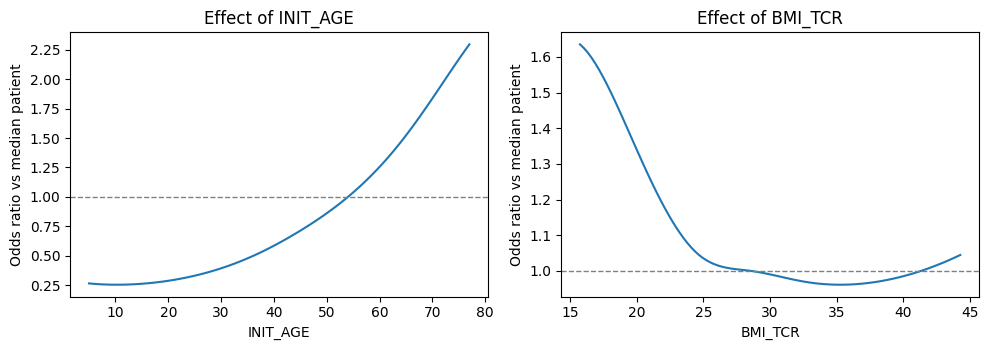

In [12]:
# Shape of the age and BMI effects: odds relative to the median patient, other features held fixed
spline_tf = pre.named_transformers_['spline']
n_sp = int(is_spline.sum())
spline_coefs = clf.coef_[0][:n_sp]          # spline block comes first in the ColumnTransformer
medians = F_final.loc[tr, SP_final].median()

fig, axes = plt.subplots(1, len(SP_final), figsize=(5 * len(SP_final), 3.6))
for ax, col in zip(np.atleast_1d(axes), SP_final):
    lo, hi = F_final.loc[tr, col].quantile([0.005, 0.995])
    grid = pd.DataFrame({c: np.full(100, medians[c]) for c in SP_final})
    grid[col] = np.linspace(lo, hi, 100)
    ref = pd.DataFrame([medians])[SP_final]
    log_odds = spline_tf.transform(grid[SP_final]) @ spline_coefs
    log_odds_ref = (spline_tf.transform(ref) @ spline_coefs)[0]
    ax.plot(grid[col], np.exp(log_odds - log_odds_ref))
    ax.axhline(1, ls='--', lw=1, color='grey')
    ax.set_xlabel(col); ax.set_ylabel('Odds ratio vs median patient')
    ax.set_title('Effect of ' + col)
plt.tight_layout(); plt.show()

*Age*

- The older a patient is when listed, the higher their odds of dying or becoming too sick for transplant within their first year on the waitlist, and the increase accelerates with age.
- Risk rises with age and the rise gets steeper. 
- By the late 70s the odds are about 2.3 times the median. From youngest to oldest that is roughly a ninefold difference, which makes age the strongest predictor in the model.

*BMI*
- Patients with a low BMI have higher odds(experiences adverse event) than a median patient, and above a BMI of about 25 it makes little difference.
- Low BMI is the risky end. At a BMI of 16 the odds are about 1.6 times the median, which fits underweight being a sign of frailty.
- From about 25 to 42 the curve is nearly flat, between 0.96 and 1.0.
- There is only a slight rise above 40, to about 1.05.
- High BMI adds almost no risk here. 

## 9. Subgroup performance (fairness)


In [13]:
res = raw.loc[te, ['GENDER', 'ETHCAT', 'ABO', 'REGION', 'INIT_AGE']].copy()
res['y'] = y_test.to_numpy()
res['p'] = p_test
res['age_group'] = pd.cut(res['INIT_AGE'], [0, 18, 40, 60, 70, 120], right=False)

def auc_ci(d, n_boot=300, seed=42):
    rng = np.random.default_rng(seed)
    y_, p_ = d['y'].to_numpy(), d['p'].to_numpy()
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_), len(y_))
        if 0 < y_[i].sum() < len(i):
            aucs.append(roc_auc_score(y_[i], p_[i]))
    return np.percentile(aucs, [2.5, 97.5])

def subgroup_auc(data, col, min_n=500, min_events=30):
    rows = []
    for g, d in data.groupby(col, observed=True):
        if len(d) < min_n or d['y'].sum() < min_events:
            continue   # too small for a stable AUC
        lo, hi = auc_ci(d)
        rows.append({'group': g, 'n': len(d), 'events': int(d['y'].sum()),
                     'event_rate': round(d['y'].mean(), 3), 'mean_pred': round(d['p'].mean(), 3),
                     'AUC': round(roc_auc_score(d['y'], d['p']), 4),
                     'CI low': round(lo, 3), 'CI high': round(hi, 3)})
    if not rows:
        print("--- " + col + ": no group has enough patients/events\n")
        return
    out = pd.DataFrame(rows)
    print("--- " + col + " | AUC gap (max-min): " + format(out['AUC'].max() - out['AUC'].min(), '.4f'))
    print(out.to_string(index=False), "\n")

print("Overall AUC:", round(roc_auc_score(res['y'], res['p']), 4), "\n")
for col in ['GENDER', 'ETHCAT', 'ABO', 'REGION']:
    subgroup_auc(res, col)

print("Reported separately (see note above):")
subgroup_auc(res, 'age_group')

Overall AUC: 0.6822 

--- GENDER | AUC gap (max-min): 0.0151
group     n  events  event_rate  mean_pred    AUC  CI low  CI high
    F 33849    1244       0.037      0.036 0.6913   0.677    0.705
    M 54429    2169       0.040      0.039 0.6762   0.664    0.687 

--- ETHCAT | AUC gap (max-min): 0.0610
 group     n  events  event_rate  mean_pred    AUC  CI low  CI high
     1 36659    1632       0.045      0.043 0.6964   0.684    0.709
     2 25522     915       0.036      0.035 0.6365   0.616    0.653
     4 17417     598       0.034      0.034 0.6975   0.679    0.717
     5  6572     199       0.030      0.028 0.6843   0.641    0.716 

--- ABO | AUC gap (max-min): 0.0866
group     n  events  event_rate  mean_pred    AUC  CI low  CI high
    A 27927    1078       0.039      0.038 0.6977   0.682    0.713
   AB  3284     111       0.034      0.038 0.6111   0.554    0.677
    B 13157     502       0.038      0.036 0.6649   0.638    0.688
    O 43303    1697       0.039      0.038 0.6820  

Does the model work equally well for different groups of patients?

**Results**

| Category | Gap | Target met? | Summary |
| --- | --- | --- | --- |
| Sex | 0.015 | Yes | The model works about equally well for women and men. |
| Race/ethnicity | 0.061 | No | The model ranks risk less well for `ETHCAT` 2. |
| Blood type | 0.087 | No | Type AB scores lowest, but the group is small, so this may be by chance. |
| Region | 0.057 | No | Missed by a small margin. |

**What stands out**

- **Race/ethnicity is the main fairness finding.**
    - `ETHCAT` 2 has an AUC of 0.637, compared with 0.684 to 0.698 for the other groups.
    - Within this group, the model is worse at telling which patients are higher risk and which are lower risk. 
- **The blood type gap is uncertain.**
    - Type AB has only 111 adverse events in the test set, so its AUC is not measured precisely (the interval runs from 0.554 to 0.677).
    - We cannot tell whether the model really works worse for type AB or whether this is noise from a small group.
- **Age groups are not counted toward the fairness target.**
    - Their AUCs (0.61 to 0.64) are lower than the overall 0.68, but this is expected.
    - Age is the model's strongest predictor. Inside a single age group everyone is a similar age, so the model loses its most useful information.



## 10. Does a longer prediction window change the picture?


In [14]:
h_rows = {}
for years in [1, 3, 5]:
    days = 365 * years
    y_h = ((raw['event_adverse'] == 1) & (raw['days_to_event'] <= days)).astype(int)
    elig_h = init_date <= FOLLOWUP_END - pd.Timedelta(days=days)
    tr_h, te_h = (~is_test & elig_h), (is_test & elig_h)
    _, _, s = fit_eval(F_final, SP_final, C=best_C, target=y_h, train=tr_h, test=te_h)
    h_rows[str(years) + '-year'] = {'train n': int(tr_h.sum()), 'test n': int(te_h.sum()),
                                    'base rate': y_h[te_h].mean(), **s}
print(pd.DataFrame(h_rows).T.round(4).to_string())

/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ 

         train n   test n  base rate  ROC-AUC  PR-AUC  PR-AUC / base  Lift@10%   Brier  Brier skill
1-year  353804.0  88278.0     0.0387   0.6822  0.0876         2.2649    2.5112  0.0364       0.0203
3-year  273843.0  68539.0     0.1147   0.6795  0.1977         1.7241    2.0229  0.0975       0.0398
5-year  202723.0  50762.0     0.1685   0.6817  0.2761         1.6385    1.8960  0.1323       0.0557


/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


**What this checks:** the main model predicts whether a patient will die or become too sick for transplant within **1 year** of listing. One year is a short time, so the same model is rebuilt to predict over **3 years** and **5 years**, to see whether a longer window gives better results.

**Terms used**

- **Base rate:** the share of patients who had an adverse event. 
- **ROC-AUC:** how well the model ranks patients by risk. 0.5 is random guessing and 1.0 is perfect.
- **PR-AUC:** how often the patients the model flags as high-risk really have an event. A model with no skill scores the same as the base rate.
- **Lift:** how many times more events are found in the 10% of patients the model rates riskiest, compared with picking patients at random.

**Results**

| Window | Patients tested | Base rate | ROC-AUC | PR-AUC | PR-AUC vs base rate | Lift |
| --- | --- | --- | --- | --- | --- | --- |
| 1 year | 88,278 | 3.9% | 0.68 | 0.088 | 2.3x | 2.5 |
| 3 years | 68,539 | 11.5% | 0.68 | 0.198 | 1.7x | 2.0 |
| 5 years | 50,762 | 16.9% | 0.68 | 0.276 | 1.6x | 1.9 |

**What this shows**

changing the window does not improve the model. Its ability to rank patients stays the same, which suggests the limit is the information available on listing day. The 1-year window is kept because it uses the most patients and is the only one that meets the lift target.